In [4]:
import glob
import json
import os
from matplotlib.patches import Polygon
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image

path = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4"

colors = ["red", "lime", "cyan", "yellow", "magenta", "orange", "blue"]
label_colors = {}

images = glob.glob(path + "/images/*.png")
labels = glob.glob(path + "/images/*.json")
masks = glob.glob(path + "/masks/*.png")

In [5]:
def json_to_bboxes(json_file, yolo=False, label_map=None):
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    img_w, img_h = data["imageWidth"], data["imageHeight"]
    boxes = []

    for shape in data.get("shapes", []):
        xs = [p[0] for p in shape["points"]]
        ys = [p[1] for p in shape["points"]]
        xmin, ymin = max(0, min(xs)), max(0, min(ys))
        xmax, ymax = min(img_w, max(xs)), min(img_h, max(ys))
        label = shape["label"]

        if yolo:
            if label_map is None:
                label_map = {}
            if label not in label_map:
                label_map[label] = len(label_map)
            boxes.append((label_map[label],
                          (xmin + xmax) / 2 / img_w, (ymin + ymax) / 2 / img_h,
                          (xmax - xmin) / img_w, (ymax - ymin) / img_h))
        else:
            # boxes.append([label, xmin, ymin, xmax, ymax])
            boxes.append([xmin, ymin, xmax, ymax])
    return boxes

  0%|          | 0/7 [00:00<?, ?it/s]

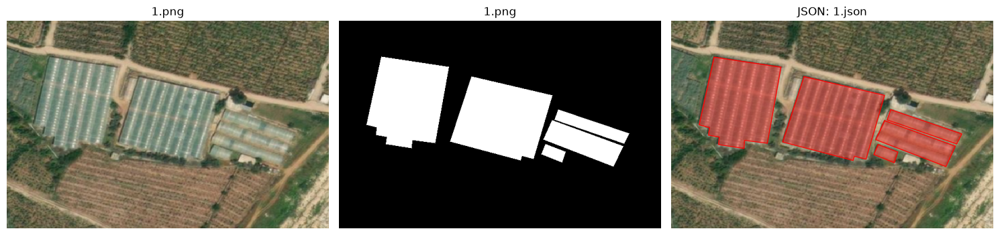

 14%|█▍        | 1/7 [00:00<00:01,  4.42it/s]

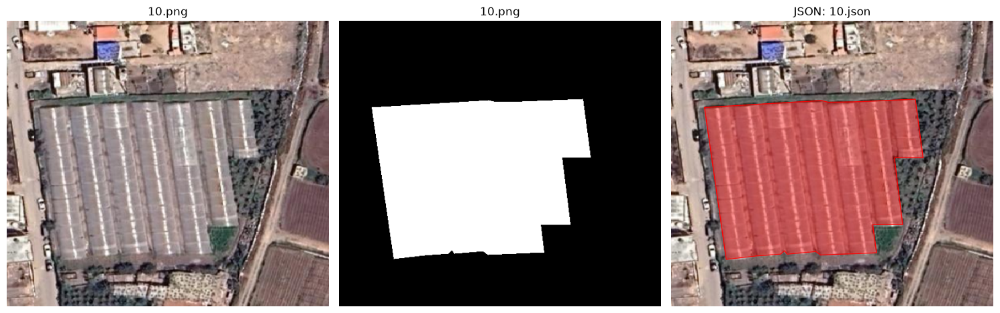

 29%|██▊       | 2/7 [00:00<00:01,  4.34it/s]

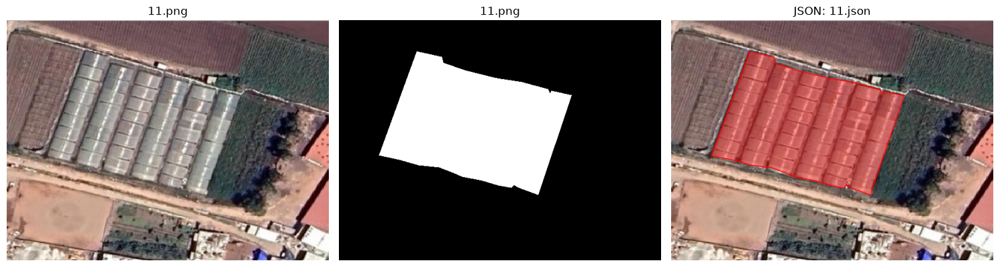

 43%|████▎     | 3/7 [00:00<00:00,  4.32it/s]

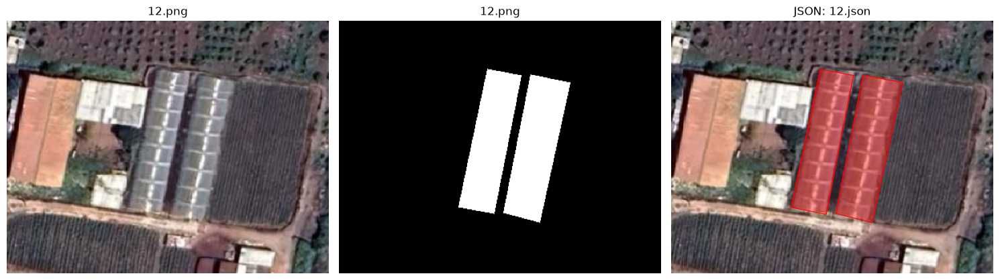

 57%|█████▋    | 4/7 [00:00<00:00,  4.52it/s]

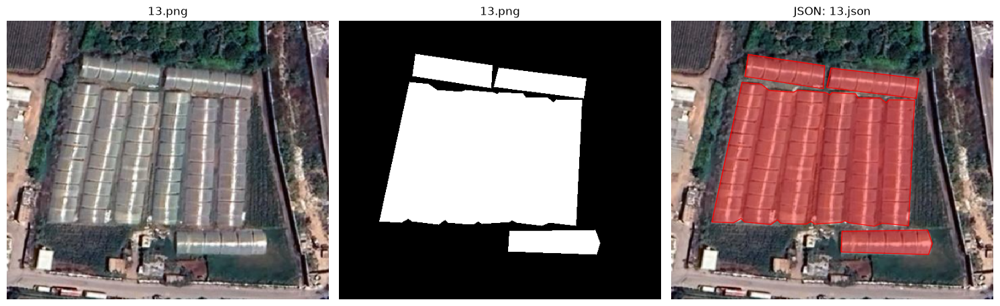

 71%|███████▏  | 5/7 [00:01<00:00,  4.44it/s]

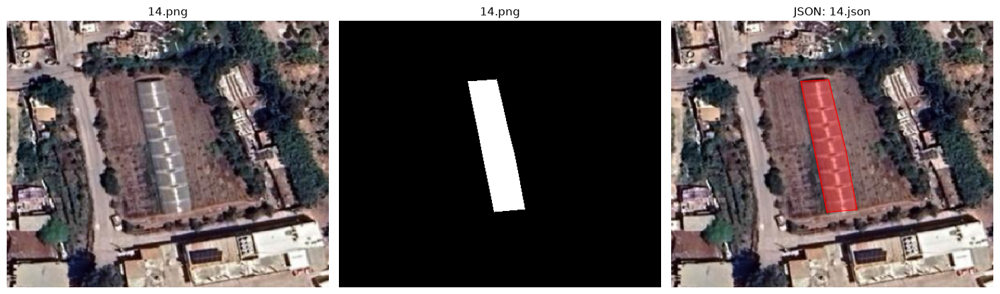

 86%|████████▌ | 6/7 [00:01<00:00,  4.53it/s]

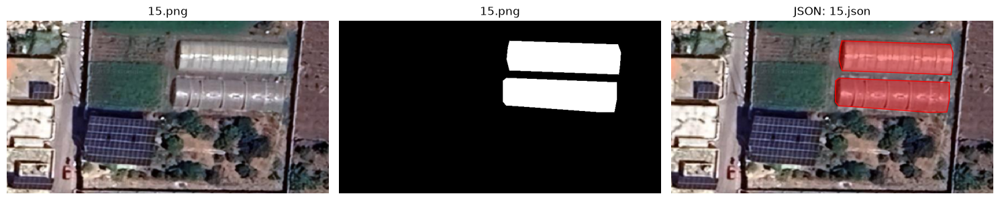

100%|██████████| 7/7 [00:01<00:00,  4.48it/s]


In [ ]:
from matplotlib.patches import Rectangle


for index, (img_path, mask_path, label_path) in tqdm(enumerate(zip(sorted(images), sorted(masks), sorted(labels))), total=len(images)):
    image = np.array(Image.open(img_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))
    with open(label_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title(os.path.basename(img_path))

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title(os.path.basename(mask_path))

    axes[2].imshow(image)
    axes[2].imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.4)
    for shape in data.get("shapes", []):
        if shape.get("shape_type", "polygon") != "polygon":
            continue
        label = shape["label"]
        if label not in label_colors:
            label_colors[label] = colors[len(label_colors) % len(colors)]
        color = label_colors[label]
 
        points = np.array(shape["points"])
        axes[2].add_patch(Polygon(points, closed=True, fill=False,
                                  facecolor=None, edgecolor=color,
                                  alpha=0.9, linewidth=1))
        # x, y = points.mean(axis=0)
        # axes[2].text(x, y, label, color="white", fontsize=9, ha="center",
        #              bbox=dict(facecolor=color, alpha=0.7, pad=1, edgecolor="none"))
    axes[2].set_title(f"JSON: {os.path.basename(label_path)}")

    # for label, x1, y1, x2, y2 in json_to_bboxes(label_path):
    #     axes[2].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
    #                                 fill=False, edgecolor="yellow", linewidth=1))

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Model summary: 178 layers, 93,735,472 parameters, 93,735,472 gradients


  0%|          | 0/1 [00:00<?, ?it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\1.png: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 1 6, 1 7, 1 8, 1 9, 1 10, 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 19, 1 20, 1 21, 1 22, 1 23, 1 24, 1 25, 3066.3ms
Speed: 7.5ms preprocess, 3066.3ms inference, 1.5ms postprocess per image at shape (1, 3, 1024, 1024)


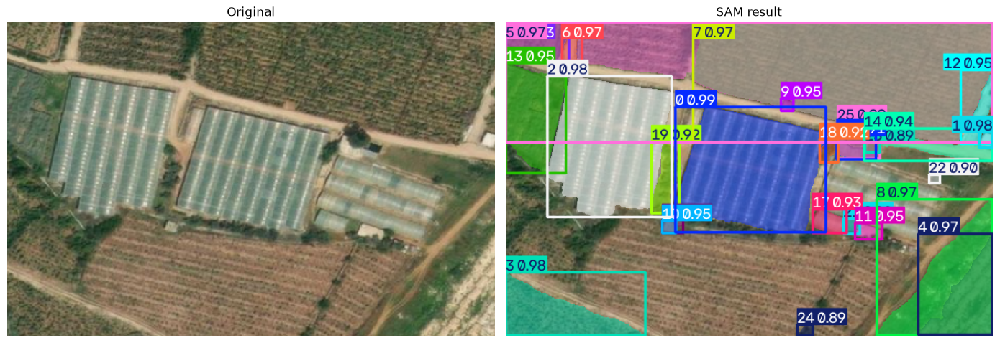

100%|██████████| 1/1 [00:03<00:00,  3.56s/it]


In [9]:
from ultralytics import SAM

# Load a model
model = SAM("sam_b.pt")

# Display model information (optional)
model.info()

img_nb = 1
for index, (img_path, label_path) in tqdm(enumerate(zip(sorted(images[:img_nb]), sorted(labels[:img_nb]))), total=len(images[:img_nb])):
    # Run inference with bboxes prompt
    results = model(img_path)

    r = results[0]

    image = np.array(Image.open(img_path).convert("RGB"))
    plotted = r.plot()[..., ::-1]   # BGR -> RGB

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[1].imshow(plotted)
    axes[1].set_title("SAM result")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

  0%|          | 0/6 [00:00<?, ?it/s]

Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)

image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\1.png: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 1 5, 13.5ms
Speed: 4.8ms preprocess, 13.5ms inference, 3.2ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


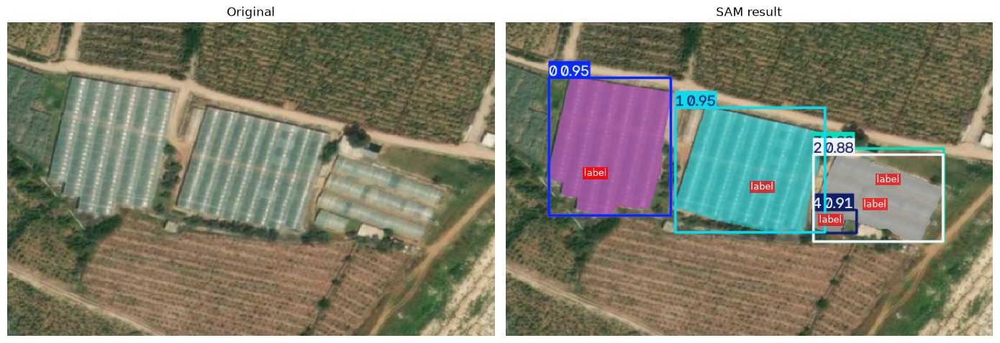

 17%|█▋        | 1/6 [00:00<00:03,  1.56it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\10.png: 1024x1024 1 0, 1 1, 6.9ms
Speed: 5.4ms preprocess, 6.9ms inference, 3.5ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


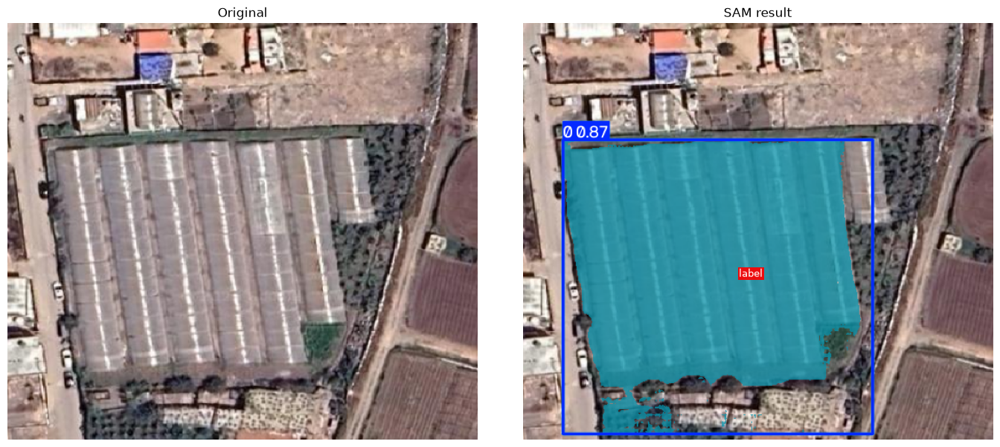

 33%|███▎      | 2/6 [00:00<00:01,  2.29it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\11.png: 1024x1024 1 0, 1 1, 18.3ms
Speed: 5.5ms preprocess, 18.3ms inference, 3.7ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


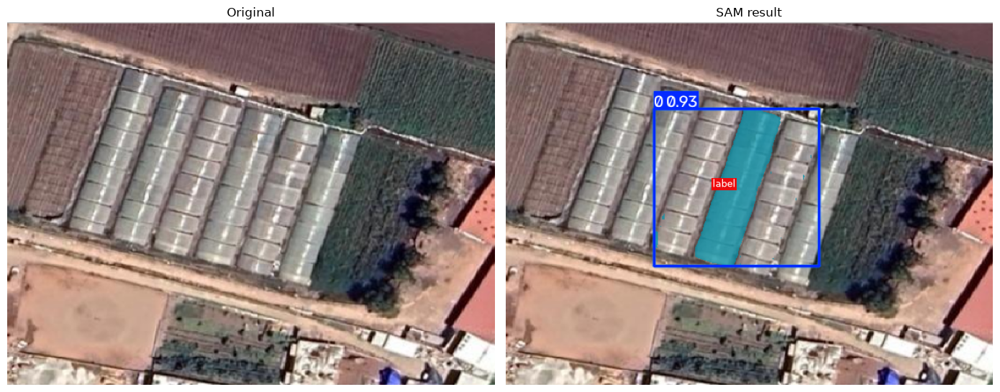

 50%|█████     | 3/6 [00:01<00:01,  2.63it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\12.png: 1024x1024 1 0, 1 1, 1 2, 11.6ms
Speed: 4.8ms preprocess, 11.6ms inference, 2.5ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


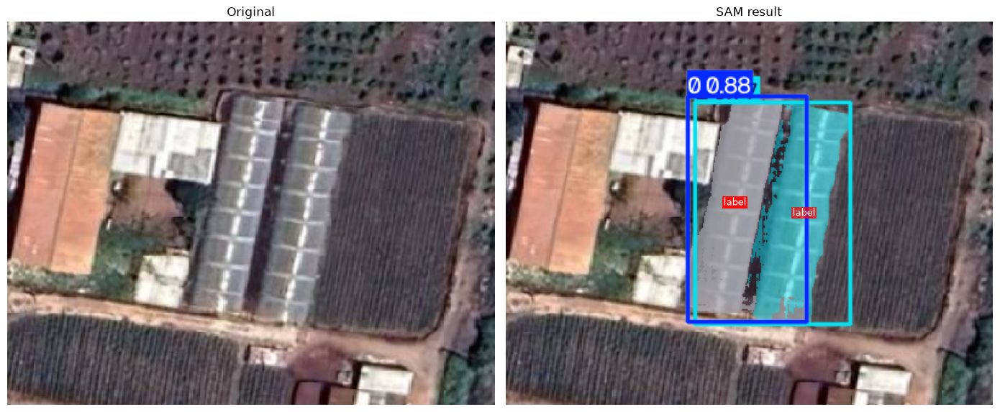

 67%|██████▋   | 4/6 [00:01<00:00,  2.94it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\13.png: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 13.9ms
Speed: 5.8ms preprocess, 13.9ms inference, 3.7ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


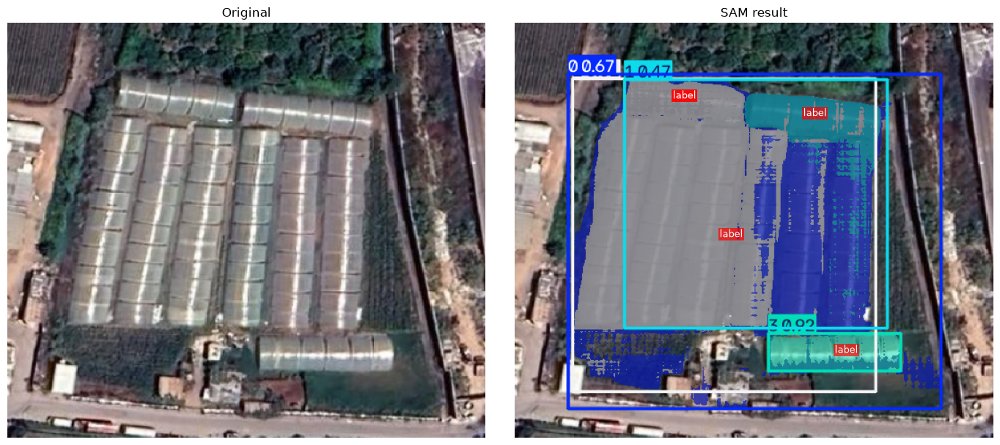

 83%|████████▎ | 5/6 [00:01<00:00,  3.05it/s]


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset4\images\14.png: 1024x1024 1 0, 1 1, 9.0ms
Speed: 10.3ms preprocess, 9.0ms inference, 3.2ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to C:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\runs\segment\predict-14


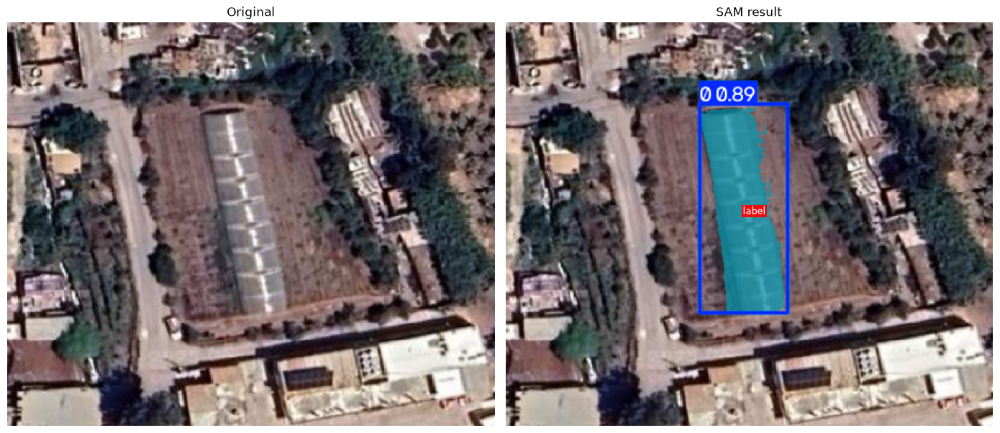

100%|██████████| 6/6 [00:02<00:00,  2.79it/s]


In [ ]:
from ultralytics.models.sam import Predictor as SAMPredictor

# Create SAMPredictor
overrides = {"conf": 0.25, "task": "segment", "mode": "predict", "imgsz": 640, "model": "mobile_sam.pt"}
predictor = SAMPredictor(overrides=overrides)


img_nb = -1
for index, (img_path, label_path, mask_path) in tqdm(enumerate(zip(sorted(images[:img_nb]), sorted(labels[:img_nb]), sorted(masks[:img_nb]))), total=len(images[:img_nb])):
    with open(label_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    predictor.set_image(img_path)  # set with image file

    # # Segment with additional args
    # results = predictor(source=img_path, crop_n_layers=1, points_stride=64, min_mask_region_area=100)

    points = []
    
    for shape in data.get("shapes", []):
        _points = np.array(shape["points"])
        x, y = _points.mean(axis=0)
        points.append((float(x), float(y)))
    points.append(points[0])  # Add a point outside the image to test negative label
    
    # Run inference with single point prompt
    results = predictor(points=points, labels=[1] * len(points))  # 1 for positive, 0 for negative

    r = results[0]

    image = np.array(Image.open(img_path).convert("RGB"))
    plotted = r.plot()[..., ::-1]   # BGR -> RGB

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[1].imshow(plotted)
    axes[1].set_title("SAM result")
    for x, y in points:
        axes[1].text(x, y, "label", color="white", fontsize=9, ha="center",
                        bbox=dict(facecolor=color, alpha=0.7, pad=1, edgecolor="none"))
    
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()